# 1. Import data / read headline

In [7]:
# imports (this is all you need for this assignment - please, do not import anything else)
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
import os


# if the present working directory is the directory of this file, change the path to the project root
if os.getcwd().endswith("notebooks"):
    os.chdir("..")

In [10]:
## Load the data
DATA_FILE = os.path.join( "data/001MoDe_R1.csv")
MARKER_FILE = os.path.join("data/001MoDe_R1.marker.csv")

In [ ]:
#define a function to read the header of the data file and return the column names
def read_header(filename):
    # Return the task parameters of the first line as a dictionary
    with open(filename) as f:
        first_line = f.readline().strip() # Read the first line and strip whitespace
    header = {}
    for item in first_line.split(";"): # Split the line by semicolon to get key-value combinations
        key, value = item.split(" ", 1)# Split each combination into key and value (only at the first space)
        # Try to convert the value to a float, if it fails, keep it as a string
        try:
            value = float(value)
        except ValueError:
            pass  # keep text values (colors, software name...) as strings
        header[key] = value
    return header



# Read the header of the data file and store the header in a dictionary
header = read_header(DATA_FILE)
print(f"Header line information in :")
#print the task paramaeters in a readable format
for key, value in header.items():
    print(f"  {key}: {value}")

Header line information in 'data/001MoDe_R1.csv':
  screenWidth: 1104.0
  screenHeight: 661.0
  cornerX: 302.0
  cornerY: 80.0
  centerX: 552.0
  centerY: 330.0
  externalRadius: 250.0
  internalRadius: 170.0
  borderRadius: 1.0
  cursorRadius: 16.0
  indexOfDifficulty: 28.00696429476858
  taskRadius: 209.5
  taskTolerance: 47.0
  borderColor: java.awt.Color[r=255,g=255,b=255]
  backgroundColor: java.awt.Color[r=0,g=0,b=0]
  cursorColorRecord: java.awt.Color[r=255,g=0,b=0]
  cursorColorWait: java.awt.Color[r=255,g=255,b=0]
  autoStart: 3600.0
  cycleMaxNumber: 6.0
  cycleDuration: 20.0
  software: LSL-mouse
  version: 1.2.0rc5
  task: CircularTarget
  isWithLSL: false


## 2. Markers and record times

Each marker line is `date,timestamp,message`. A line is a marker when its 2nd field is an integer timestamp.
The lines that come after the last marker are the summary table written by MouseReMoCo (we keep them to compare with our own results later).

A record starts at a `DoRecord` marker and ends at the **next** marker (normally `DoPause`; for a last record that is interrupted it can be `WINDOW_CLOSING`).
In this file 6 records were planned (`ToDo=6`) but the window was closed during the 5th pause, so there are only 5 records (`Rec006` is empty in the table).

In [ ]:
# Function to read-marker of file, and one to return the list of timestamp_ms.

def read_markers(filename):
    # Return the list of timestamp_ms, message and the list of the summary table lines
    with open(filename) as f:
        lines = f.read().splitlines()
    markers, table_lines = [], []
    for line in lines[3:]:  # skip header, date and empty line
        parts = line.split(",", 2)
        if len(parts) == 3 and parts[1].strip().isdigit():
            markers.append((int(parts[1]), parts[2]))
        elif line.strip() != "":
            table_lines.append(line)
    return markers, table_lines


#call the function and print the markers and the summary table lines
markers, table_lines = read_markers(MARKER_FILE)
print(f"Markers in '{MARKER_FILE}':")
for ts, msg in markers: # for every marker, print the timestamp and the message
    print(f"{ts}: {msg}")
for line in table_lines: #same for the summary table lines
    print(line)




def get_record_times(markers):
    # Return an array (n_records, 2) with [start, end] timestamps (ms) of each record
    times = []
    for i, (ts, msg) in enumerate(markers): # enumerate over the markers to get the index and the (timestamp, message) 
        if "DoRecord" in msg and i + 1 < len(markers): # check if the message contains "DoRecord" and if there is a next marker then stock the start timestamp and the next marker's timestamp as the end timestamp to isolate a record
            times.append([ts, markers[i + 1][0]])
    return np.array(times, dtype=np.int64)

#call the function and print the record times
record_times = get_record_times(markers)
print("record times (ms):")
for start, end in record_times:
    print(f"{start} to {end} ({(end - start) / 1000:.3f} s)")

Markers in 'data/001MoDe_R1.marker.csv':
1616776712325: KeyTyped=32 DoCycleChange
1616776712331: DoCycleChange:DoStartCycleTimedSequence
1616776712333: DoCycleChange:DoRecord RecordDone=0 PauseDone=0 ToDo=6
1616776732336: DoCycleChange:DoPause RecordDone=1 PauseDone=0 ToDo=6
1616776752340: DoCycleChange:DoRecord RecordDone=1 PauseDone=1 ToDo=6
1616776772351: DoCycleChange:DoPause RecordDone=2 PauseDone=1 ToDo=6
1616776792372: DoCycleChange:DoRecord RecordDone=2 PauseDone=2 ToDo=6
1616776812386: DoCycleChange:DoPause RecordDone=3 PauseDone=2 ToDo=6
1616776832390: DoCycleChange:DoRecord RecordDone=3 PauseDone=3 ToDo=6
1616776852404: DoCycleChange:DoPause RecordDone=4 PauseDone=3 ToDo=6
1616776872419: DoCycleChange:DoRecord RecordDone=4 PauseDone=4 ToDo=6
1616776892433: DoCycleChange:DoPause RecordDone=5 PauseDone=4 ToDo=6
1616776898364: KeyTyped=113 WINDOW_CLOSING
1616776898367: 
    Var , nLaps ,      Re ,      Te ,   error ,  MT/lap , IDe/lap ,      Be ,     IPe ,
   unit ,   lap ,   p

## 3. Data

We read the numbers with `np.loadtxt`, skipping the lines before the column names. We look for the column names line instead of assuming it is line 4, and we pick columns **by name**, so the code still works if a newer MouseReMoCo version adds columns.

**Change of coordinates** (the key step):
* the origin is moved to the centre of the circle: `x = mouseX − centerX`;
* the screen y axis points **down**, so we flip it: `y = centerY − mouseY`. Now y points up, like in a normal plot, and counter-clockwise rotation gives positive angles.
* time is converted to seconds since the first sample: `t = (timestamp − timestamp[0]) / 1000`.

**N.B:** between two records, MouseReMoCo writes a line `0,0,0,0`. If we keep these 5 lines, the time series gets points at t ≈ −1.6 billion s and the trajectory gets lines going to the top-left corner of the screen (mouse at pixel (0, 0)). We remove every line whose timestamp is 0 to avoid erroer in data process.

In [ ]:
#Define a function to read the data file and his parameters and return the data as a numpy array
def read_data(filename,header):
        # Return t (s), x, y (pixels, centred, y up), inside (bool), timestamps (ms)
        
    with open(filename) as f:
        lines = f.read().splitlines() # read all lines of the file
    i_names = next(i for i, line in enumerate(lines) if line.startswith("timestamp")) # find the index of the line that starts with "timestamp" (the column names)
    names = lines[i_names].split(",") #then split the line by comma to get the column names in the timestamp line 
    data = np.loadtxt(filename, delimiter=",", skiprows=i_names + 1) # load the data as a numpy array, skipping the header lines
    data = data[data[:, names.index("timestamp")] > 0]  # remove the "0,0,0,0" separator lines by keeping only the rows where the timestamp is greater than 0
    timestamps = data[:, names.index("timestamp")].astype(np.int64) #as time stamps can be very large, we need to use int64 to avoid overflow

# get x and y coordinates relative to the center of the target (pixels)
    x = data[:, names.index("mouseX")] - header["centerX"] # compute the mouse x coordinate relative to the center of the target by doing mouseX - centerX
    y = header["centerY"] - data[:, names.index("mouseY")] #same for Y
    inside = data[:, names.index("mouseInTarget")] == 1 # As defined in documentation, 1 mean inside the target, 0 means outside. So we can create a boolean array where True means inside and False means outside by checking if mouseInTarget is equal to 1
    t = (timestamps - timestamps[0]) / 1000 #define the time vector in seconds, relative to the first timestamp
    return t, x, y, inside, timestamps


t, x, y, inside, timestamps = read_data(DATA_FILE, header) #alling the function
t0 = timestamps[0]  # time origin (ms) used for all the plots

print("record times (seconds since the first data sample):")
for start, end in record_times:
    #keep the same format as before, but convert the timestamps to seconds since the first data sample
    print(f"{(start - t0) / 1000:7.3f} to {(end - t0) / 1000:7.3f} ({(end - start) / 1000:.3f} s)")

NameError: name 'names' is not defined

## 4. Raw data plots

Two plots of all the samples: x and y versus time (with the start / end of each record as vertical lines), then the trajectory in the (x, y) plane with the samples inside the target in green and the two edges of the ring in red.
Nothing is recorded during the pauses, which is why there are holes in the time series.

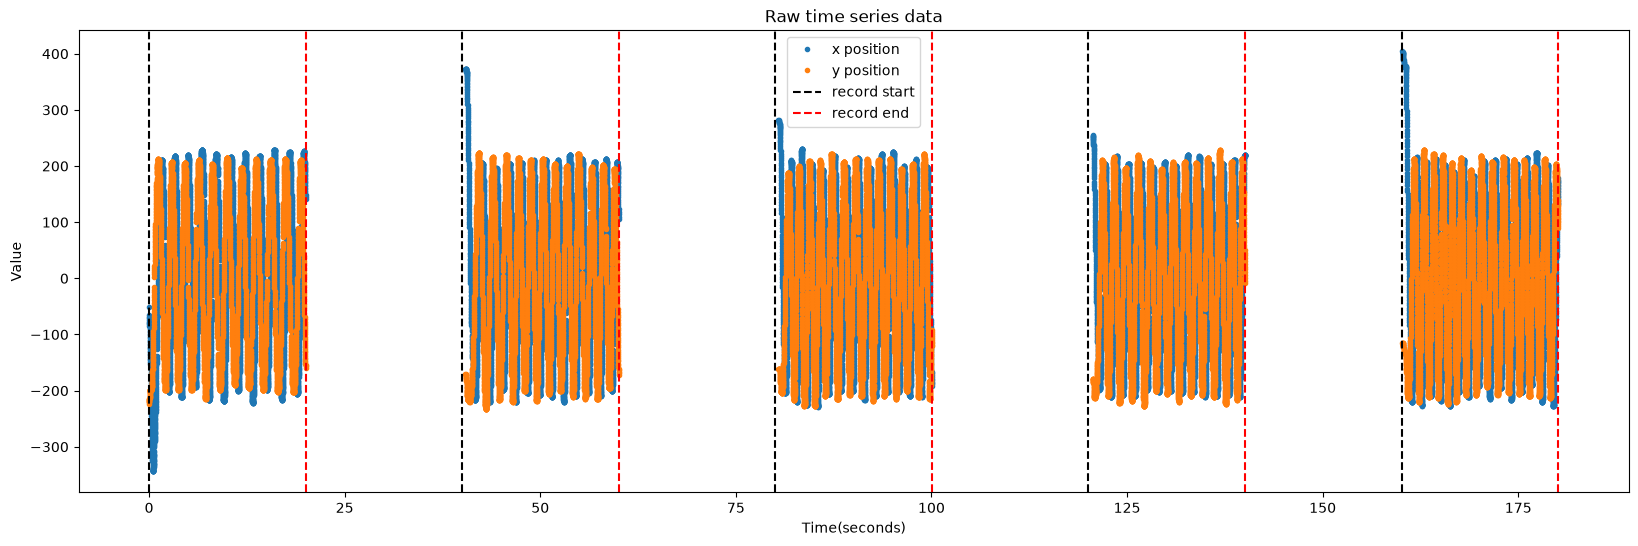

In [ ]:
def plot_raw_timeseries(t, x, y, record_times, t0):
    fig, ax = plt.subplots(figsize=(20, 6))#def the figure size
    ax.plot(t, x, ".", label="x position")# plot the x(mouse) position by time 
    ax.plot(t, y, ".", label="y position")# plot the y(mouse) position by time + name

    # we set a line for each record start and end, with a different color and a label for the first one
    for i, (start, end) in enumerate(record_times): 
        ax.axvline((start - t0) / 1000, color="k", linestyle="--", label="record start" if i == 0 else None) #at start time(DoRecord in data file) add a vertical line 
        ax.axvline((end - t0) / 1000, color="r", linestyle="--", label="record end" if i == 0 else None) #at start time(DoRecord in data file) add a vertical line 
     # set the labels and title of the plot   
    ax.set_xlabel("Time(seconds)")
    ax.set_ylabel("Value")
    ax.set_title("Raw time series data")
    ax.legend()
    plt.show()

plot_raw_timeseries(t, x, y, record_times, t0)

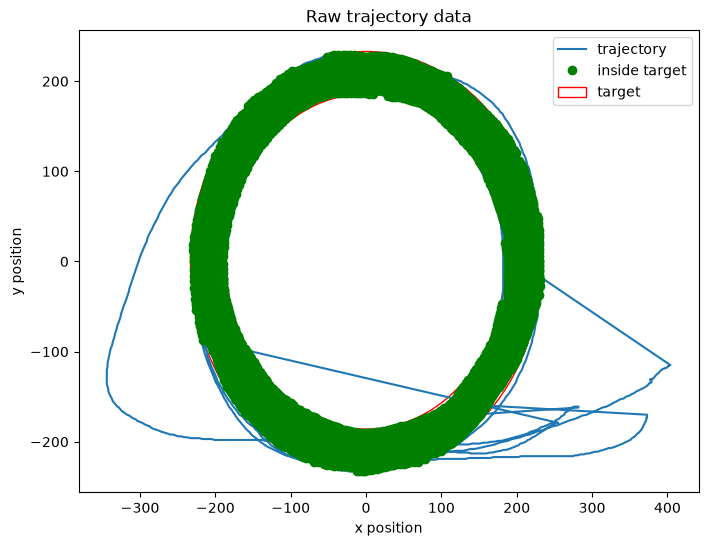

In [27]:
def plot_raw_trajectory(x, y, inside, header):
    #Call the function with the x and y coordinates,array indicating if  mouse is inside the target, and the task parameters 
    #return a plot of the trajectory with the target area and the points inside the target highlighted
    # Input:
    #   x: array of x coordinates
    #   y: array of y coordinates
    #   inside: boolean array indicating if the mouse is inside the target
    #   header: dictionary containing the task parameters
    # Output:
    #   None (displays the plot)
    R, T = header["taskRadius"], header["taskTolerance"]
    fig, ax = plt.subplots(figsize=(8, 6))
    # plot the trajectory as a line plot, with the points inside the target highlighted in green
    ax.plot(x, y, label="trajectory")
    ax.plot(x[inside], y[inside], "go", label="inside target")
    #use the Circle patch to draw the target area, with a radius of R + T/2, centered at (0,0)
    ax.add_patch(Circle((0, 0), R + T / 2, fill=False, edgecolor="r", label="target"))
    # draw the inner circle, with a radius of R - T/2, centered at (0,0)
    ax.add_patch(Circle((0, 0), R - T / 2, fill=False, edgecolor="r"))
    ax.set_xlabel("x position")
    ax.set_ylabel("y position")
    ax.set_title("Raw trajectory data")
    ax.legend()
    plt.show()


plot_raw_trajectory(x, y, inside, header)

Now that we can isolate each record in a trials by checking when it's "DoRecord" or "DoPause" by function, we can comapre data from a record to another in list.


In [ ]:
def split_records(t, x, y, inside, timestamps, record_times):
    # Return a list of records, each record is a dictionary with keys "t", "x", "y", "inside"
    records = [] #list to store the records
    for start, end in record_times: 
        #By using the record times, isolate the data for each record by creating a boolean mask that selects the samples within the start and end timestamps.
        #We then append a dictionary containing the time, x, y, and inside arrays for each record to the records list.
        m = (timestamps >= start) & (timestamps <= end)
        records.append({"t": t[m], "x": x[m], "y": y[m], "inside": inside[m]})
    return records

#Print the number of records and the number of samples in each record, as well as the start and end times of each record, and the duration and sampling frequency of each record
records = split_records(t, x, y, inside, timestamps, record_times)
print(f"Number of records: {len(records)}")
for i, r in enumerate(records):
    n, t_start, t_end = len(r["t"]), r["t"][0], r["t"][-1]
    duration = t_end - t_start
    print(f"record {i}: {n} samples from {t_start:7.3f} to {t_end:7.3f} s, ({duration:.3f}s, {(n - 1) / duration:.3f} Hz)")

Number of records: 5
record 0: 3971 samples from   0.022 to  20.004 s, (19.982s, 198.679 Hz)
record 1: 3898 samples from  40.429 to  60.018 s, (19.589s, 198.938 Hz)
record 2: 3898 samples from  80.371 to 100.050 s, (19.679s, 198.028 Hz)
record 3: 3884 samples from 120.608 to 140.069 s, (19.461s, 199.527 Hz)
record 4: 3936 samples from 160.146 to 180.098 s, (19.952s, 197.223 Hz)
